In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import patsy
from scipy import stats
import warnings
warnings.simplefilter("ignore", FutureWarning)
METABOTKIT = r'C:\Users\jaileru\Projects\metabolomics-toolkit'
ROOT = r"\\172.22.48.112\Sumner_HHEAR_Lichtveld\4a. Data_LC-MS_OrbiTrap\5-Statistical Analyses\Julian Analysis\July-2026"
import sys,os
sys.path.append(os.path.abspath(METABOTKIT))
from differential_abundance import DifferentialAbundance
from dimensionality_reduction import pca_plot
PROJECT_ID = 'ST002118'
from itertools import chain
from docx import Document
sys.path.append(os.path.abspath(os.path.join(ROOT, "Analysis")))
from ST002118 import *

In [2]:
untargeted_data = clean_untargeted_reference(rf'{ROOT}/Data/Untargeted/reference_copy_untargeted_data.parquet')
categorical_data = clean_categorical_reference(rf'{ROOT}/Data/Untargeted/reference_copy_categorical_data.parquet',
                                               additional_cols=['v113a','v113b','v113c','v113d','v108a','v107g'])
ethnicity_map = {"v113a":'Ethnicity9Categories',
                 "v113b":"Ethnicity8Categories",
                 'v113c':"Ethnicity7Categories",
                 'v113d':"Ethnicity6Categories",
                 'v108a':"DistrictAtIntake10Categories",
                 'v107g':'MaternalAgeAtIntake3Categories'}
categorical_data = categorical_data.rename(columns=ethnicity_map)

In [3]:
targeted_file = rf"{ROOT}/Data/Targeted/TARGETED_DATA_WIDE_06302026.xlsx"
targeted_data = pd.read_excel(targeted_file)
targeted_data.columns = ['CompositeKey','Cd(ng/mL)','Hg(ng/mL)','Mn(ng/mL)','Pb(ug/mL)','Se(ng/mL)','Sn(ng/mL)','SID_MW']
for col in targeted_data.columns:
    targeted_data[col] = targeted_data[col].str.replace("ng/mL","")
    targeted_data[col] = targeted_data[col].str.replace("ug/mL","")
    targeted_data[col] = targeted_data[col].str.replace("ug/dL","")
targeted_data = targeted_data.set_index("SID_MW")

In [4]:
t1_untargeted_data = untargeted_data.loc[categorical_data[categorical_data['Trimester_n'] == 1].index,:]
t1_targeted_data = targeted_data.loc[targeted_data.index.intersection(t1_untargeted_data.index)]
t2_untargeted_data = untargeted_data.loc[categorical_data[categorical_data['Trimester_n'] == 3].index,:]
t2_targeted_data = targeted_data.loc[targeted_data.index.intersection(t2_untargeted_data.index)]

In [5]:
ethnicity_map = {
    "1.0": "Creole",
    "2.0": "Hindustani",
    "3.0": "Indigenous",
    "4.0": "Javanese",
    "5.0": "Maroon",
    "6.0": "Mixed"
}

district_map = {"1.0":"Paramaribo",
                "2.0":"Wanica",
                "3.0":"Commewijne",
                "4.0":"Marowijne",
                "5.0":"Saramacca",
                "6.0":"Coronie",
                "7.0":"Nickerie",
                "8.0":"Para",
                "9.0":"Brokopondo",
                "10.0":"Sipaliwini"}
maternal_age_map = {"1.0":"16-19 years",
                    "2.0": "20-34 years",
                    "3.0": "35+ years"}

In [6]:
t1_targeted_data['Ethnicity6'] = categorical_data.loc[t1_targeted_data.index,'Ethnicity6Categories']
t2_targeted_data['Ethnicity6'] = categorical_data.loc[t2_targeted_data.index,'Ethnicity6Categories']

t1_targeted_data['DistrictAtIntake'] = categorical_data.loc[t1_targeted_data.index,'DistrictAtIntake10Categories']
t2_targeted_data['DistrictAtIntake'] = categorical_data.loc[t2_targeted_data.index,'DistrictAtIntake10Categories']

t1_targeted_data['MaternalAgeAtIntake'] = categorical_data.loc[t1_targeted_data.index,"MaternalAgeAtIntake3Categories"]
t2_targeted_data['MaternalAgeAtIntake'] = categorical_data.loc[t2_targeted_data.index,"MaternalAgeAtIntake3Categories"]

t1_targeted_data['PretermBirthLessThan37weeks'] = categorical_data.loc[t1_targeted_data.index,'PretermBirthLessThan37weeks']
t2_targeted_data['PretermBirthLessThan37weeks'] = categorical_data.loc[t2_targeted_data.index,'PretermBirthLessThan37weeks']


t1_targeted_data['BirthweightLessThan2500g'] = categorical_data.loc[t1_targeted_data.index,'BirthweightLessThan2500g']
t2_targeted_data['BirthweightLessThan2500g'] = categorical_data.loc[t2_targeted_data.index,'BirthweightLessThan2500g']

In [7]:
mercury_exposure_t1 = t1_targeted_data[['Hg(ng/mL)','Ethnicity6','DistrictAtIntake','PretermBirthLessThan37weeks','BirthweightLessThan2500g','MaternalAgeAtIntake']].copy()
mercury_exposure_t1['Ethnicity6'] = mercury_exposure_t1['Ethnicity6'].dropna().astype(str).map(ethnicity_map)
mercury_exposure_t1['DistrictAtIntake'] = mercury_exposure_t1['DistrictAtIntake'].dropna().astype(str).map(district_map)
mercury_exposure_t1['MaternalAgeAtIntake'] = mercury_exposure_t1['MaternalAgeAtIntake'].dropna().astype(str).map(maternal_age_map)
mercury_exposure_t1['Hg(ng/mL)'] = mercury_exposure_t1['Hg(ng/mL)'].astype(float)
mercury_exposure_t1.loc[mercury_exposure_t1['Hg(ng/mL)'] <= 5.8,'EPA Limit'] = "Normal"
mercury_exposure_t1.loc[mercury_exposure_t1['Hg(ng/mL)'] > 5.8,'EPA Limit'] = "High"
mask = (mercury_exposure_t1['DistrictAtIntake'].value_counts() >= 30)
large_districts = mercury_exposure_t1['DistrictAtIntake'].value_counts()[mask]

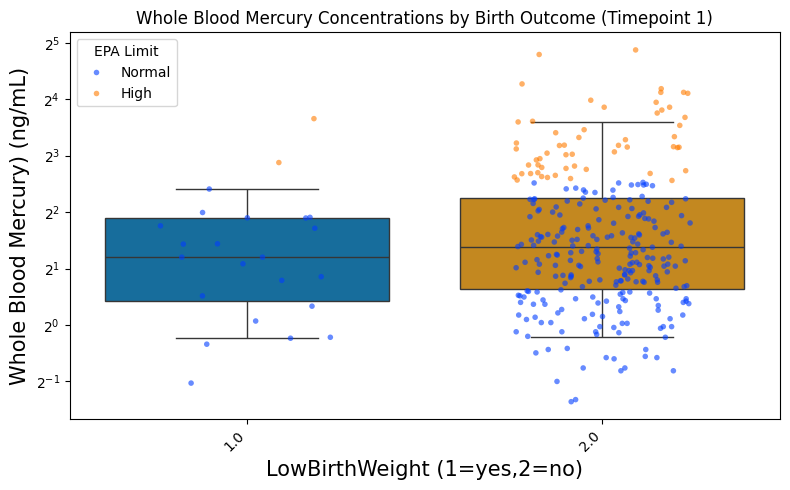

BirthweightLessThan2500g
2.0    283
1.0     23
Name: count, dtype: int64

In [8]:
import matplotlib.ticker as ticker
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=mercury_exposure_t1,
    x="BirthweightLessThan2500g",
    y="Hg(ng/mL)",
    hue="BirthweightLessThan2500g",
    whis=[5,95],
    palette="colorblind",
    legend=False,
    fliersize=0,
    ax=ax
)

sns.stripplot(
    data=mercury_exposure_t1,
    x='BirthweightLessThan2500g',
    y="Hg(ng/mL)",
    hue="EPA Limit",
    jitter=0.25,
    alpha=0.6,
    size=4,
    ax=ax,
    dodge=False,  # keeps all tertiles on the same x-position instead of splitting
    legend=True,
    palette='bright'
)

ax.set_xlabel("LowBirthWeight (1=yes,2=no)",fontsize=15)
ax.set_ylabel("Whole Blood Mercury) (ng/mL)",fontsize=15)
ax.set_title("Whole Blood Mercury Concentrations by Birth Outcome (Timepoint 1)")
ax.set_yscale('log',base=2)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
mercury_exposure_t1['BirthweightLessThan2500g'].value_counts()

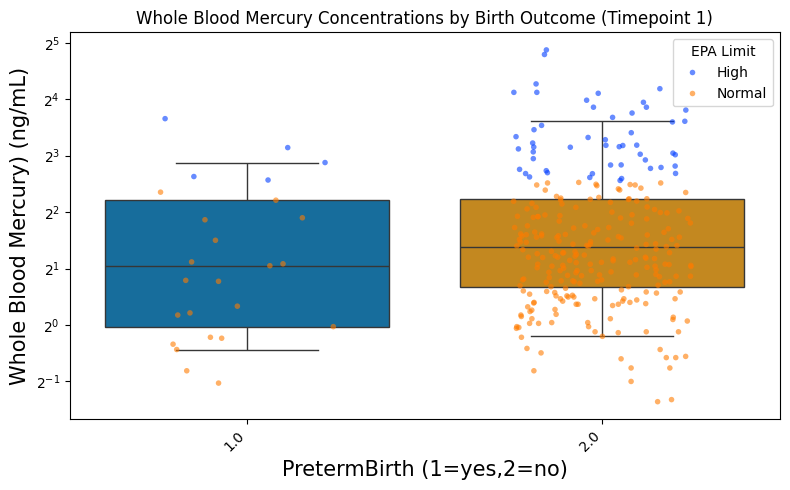

PretermBirthLessThan37weeks
2.0    275
1.0     25
Name: count, dtype: int64

In [188]:
import matplotlib.ticker as ticker
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=mercury_exposure_t1,
    x="PretermBirthLessThan37weeks",
    y="Hg(ng/mL)",
    hue="PretermBirthLessThan37weeks",
    whis=[5,95],
    palette="colorblind",
    legend=False,
    fliersize=0,
    ax=ax
)

sns.stripplot(
    data=mercury_exposure_t1,
    x='PretermBirthLessThan37weeks',
    y="Hg(ng/mL)",
    hue="EPA Limit",
    jitter=0.25,
    alpha=0.6,
    size=4,
    ax=ax,
    dodge=False,  # keeps all tertiles on the same x-position instead of splitting
    legend=True,
    palette='bright'
)

ax.set_xlabel("PretermBirth (1=yes,2=no)",fontsize=15)
ax.set_ylabel("Whole Blood Mercury) (ng/mL)",fontsize=15)
ax.set_title("Whole Blood Mercury Concentrations by Birth Outcome (Timepoint 1)")
ax.set_yscale('log',base=2)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
mercury_exposure_t1['PretermBirthLessThan37weeks'].value_counts()

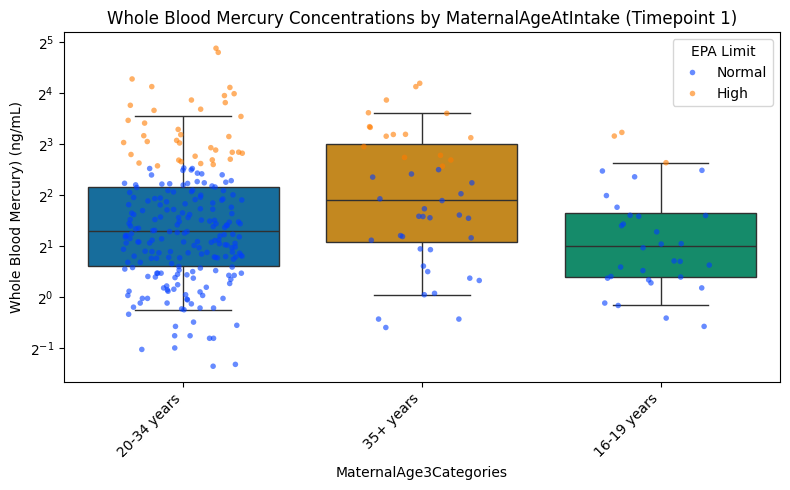

MaternalAgeAtIntake
20-34 years    234
35+ years       44
16-19 years     32
Name: count, dtype: int64

In [193]:
import matplotlib.ticker as ticker
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=mercury_exposure_t1,
    x="MaternalAgeAtIntake",
    y="Hg(ng/mL)",
    hue="MaternalAgeAtIntake",
    whis=[5,95],
    palette="colorblind",
    legend=False,
    fliersize=0,
    ax=ax
)

sns.stripplot(
    data=mercury_exposure_t1,
    x='MaternalAgeAtIntake',
    y="Hg(ng/mL)",
    hue="EPA Limit",
    jitter=0.25,
    alpha=0.6,
    size=4,
    ax=ax,
    dodge=False,  # keeps all tertiles on the same x-position instead of splitting
    legend=True,
    palette='bright'
)

ax.set_xlabel("MaternalAge3Categories")
ax.set_ylabel("Whole Blood Mercury) (ng/mL)")
ax.set_title("Whole Blood Mercury Concentrations by MaternalAgeAtIntake (Timepoint 1)")
ax.set_yscale('log',base=2)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
mercury_exposure_t1['MaternalAgeAtIntake'].value_counts()

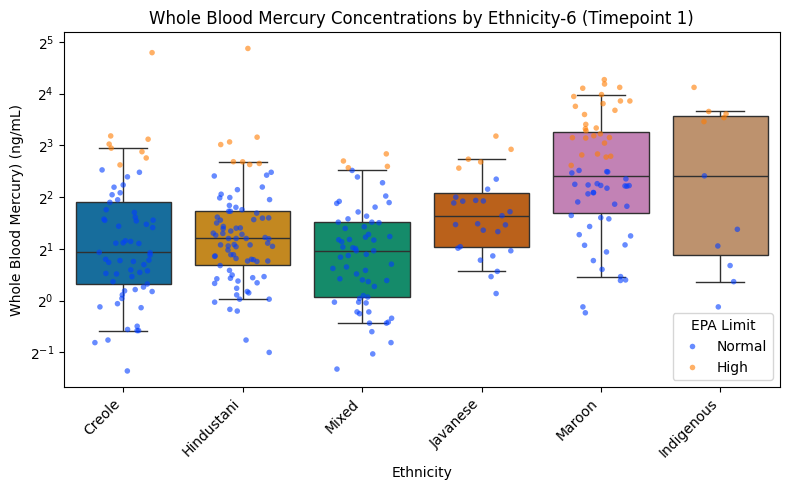

Ethnicity6
Hindustani    82
Creole        65
Mixed         62
Maroon        62
Javanese      27
Indigenous    11
Name: count, dtype: int64

In [192]:
import matplotlib.ticker as ticker
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=mercury_exposure_t1,
    x="Ethnicity6",
    y="Hg(ng/mL)",
    hue="Ethnicity6",
    whis=[5,95],
    palette="colorblind",
    legend=False,
    fliersize=0,
    ax=ax
)

sns.stripplot(
    data=mercury_exposure_t1,
    x='Ethnicity6',
    y="Hg(ng/mL)",
    hue="EPA Limit",
    jitter=0.25,
    alpha=0.6,
    size=4,
    ax=ax,
    dodge=False,  # keeps all tertiles on the same x-position instead of splitting
    legend=True,
    palette='bright'
)

ax.set_xlabel("Ethnicity")
ax.set_ylabel("Whole Blood Mercury) (ng/mL)")
ax.set_title("Whole Blood Mercury Concentrations by Ethnicity-6 (Timepoint 1)")
ax.set_yscale('log',base=2)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
mercury_exposure_t1['Ethnicity6'].value_counts()

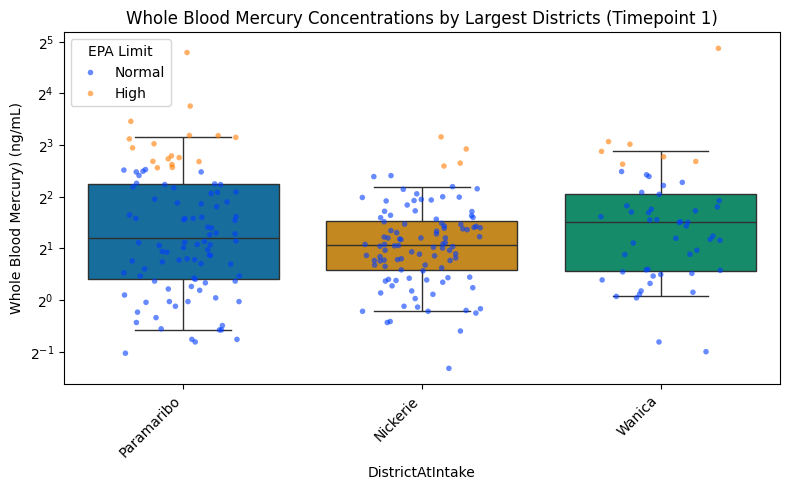

DistrictAtIntake
Nickerie      104
Paramaribo    100
Wanica         52
Sipaliwini     28
Para           10
Commewijne      6
Brokopondo      4
Marowijne       2
Saramacca       2
Coronie         1
Name: count, dtype: int64

In [194]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=mercury_exposure_t1[mercury_exposure_t1['DistrictAtIntake'].isin(large_districts.index)],
    x="DistrictAtIntake",
    y="Hg(ng/mL)",
    hue="DistrictAtIntake",
    whis=[5,95],
    palette="colorblind",
    legend=False,
    fliersize=0,
    ax=ax
)

sns.stripplot(
    data=mercury_exposure_t1[mercury_exposure_t1['DistrictAtIntake'].isin(large_districts.index)],
    x='DistrictAtIntake',
    y="Hg(ng/mL)",
    hue="EPA Limit",
    jitter=0.25,
    alpha=0.6,
    size=4,
    ax=ax,
    dodge=False,  # keeps all tertiles on the same x-position instead of splitting
    legend=True,
    palette='bright'
)

ax.set_xlabel("DistrictAtIntake")
ax.set_ylabel("Whole Blood Mercury) (ng/mL)")
ax.set_yscale("log",base=2)
ax.set_title("Whole Blood Mercury Concentrations by Largest Districts (Timepoint 1)")
#ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=10))
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
mercury_exposure_t1['DistrictAtIntake'].value_counts()

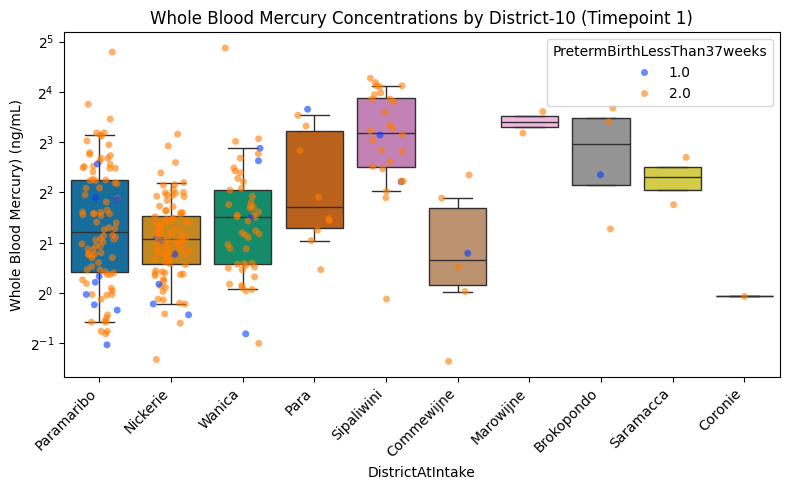

DistrictAtIntake
Nickerie      104
Paramaribo    100
Wanica         52
Sipaliwini     28
Para           10
Commewijne      6
Brokopondo      4
Marowijne       2
Saramacca       2
Coronie         1
Name: count, dtype: int64

In [182]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=mercury_exposure_t1,
    x="DistrictAtIntake",
    y="Hg(ng/mL)",
    hue="DistrictAtIntake",
    whis=[5,95],
    palette="colorblind",
    legend=False,
    fliersize=0,
    ax=ax
)

sns.stripplot(
    data=mercury_exposure_t1,
    x='DistrictAtIntake',
    y="Hg(ng/mL)",
    hue="PretermBirthLessThan37weeks",
    jitter=0.25,
    alpha=0.6,
    size=5,
    ax=ax,
    dodge=False,  # keeps all tertiles on the same x-position instead of splitting
    legend=True,
    palette='bright'
)

ax.set_xlabel("DistrictAtIntake")
ax.set_ylabel("Whole Blood Mercury) (ng/mL)")
ax.set_yscale("log",base=2)
ax.set_title("Whole Blood Mercury Concentrations by District-10 (Timepoint 1)")
#ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=10))
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
mercury_exposure_t1['DistrictAtIntake'].value_counts()

In [175]:
mercury_exposure_t1

,Hg(ng/mL),Ethnicity6,DistrictAtIntake,PretermBirthLessThan37weeks,BirthweightLessThan2500g,MaternalAgeAtIntake,EPA Limit
Lich_S_69,5.76,Creole,Paramaribo,2.0,2.0,20-34 years,Normal
Lich_S_449,4.42,Hindustani,Nickerie,2.0,2.0,20-34 years,Normal
Lich_S_627,1.05,Mixed,Wanica,2.0,1.0,35+ years,Normal
Lich_S_643,3.12,Javanese,Nickerie,2.0,2.0,20-34 years,Normal
Lich_S_428,2.27,Mixed,Nickerie,2.0,2.0,35+ years,Normal
...,...,...,...,...,...,...,...
Lich_S_328,1.38,Javanese,Para,2.0,2.0,20-34 years,Normal
Lich_S_216,1.34,Mixed,Paramaribo,2.0,2.0,20-34 years,Normal
Lich_S_383,4.85,Mixed,Wanica,2.0,2.0,20-34 years,Normal
Lich_S_614,2.23,Creole,Wanica,2.0,2.0,35+ years,Normal


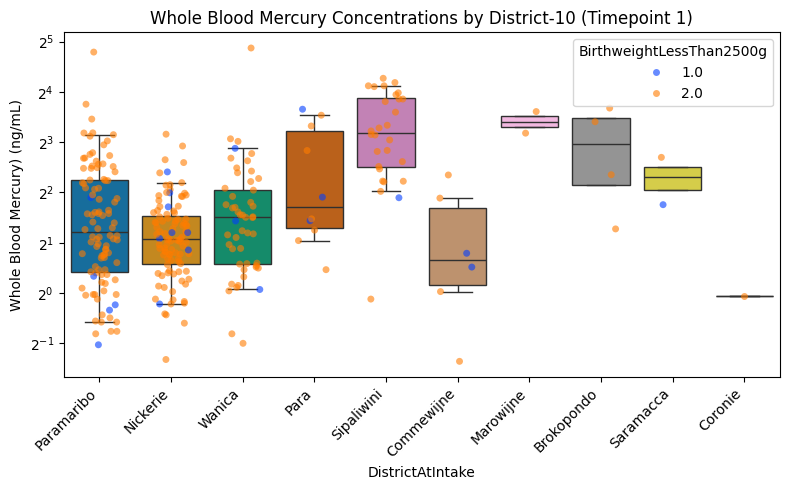

DistrictAtIntake
Nickerie      104
Paramaribo    100
Wanica         52
Sipaliwini     28
Para           10
Commewijne      6
Brokopondo      4
Marowijne       2
Saramacca       2
Coronie         1
Name: count, dtype: int64

In [181]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=mercury_exposure_t1,
    x="DistrictAtIntake",
    y="Hg(ng/mL)",
    hue="DistrictAtIntake",
    whis=[5,95],
    palette="colorblind",
    legend=False,
    fliersize=0,
    ax=ax
)

sns.stripplot(
    data=mercury_exposure_t1,
    x='DistrictAtIntake',
    y="Hg(ng/mL)",
    hue="BirthweightLessThan2500g",
    jitter=0.25,
    alpha=0.6,
    size=5,
    ax=ax,
    dodge=False,  # keeps all tertiles on the same x-position instead of splitting
    legend=True,
    palette='bright'
)

ax.set_xlabel("DistrictAtIntake")
ax.set_ylabel("Whole Blood Mercury) (ng/mL)")
ax.set_yscale("log",base=2)
ax.set_title("Whole Blood Mercury Concentrations by District-10 (Timepoint 1)")
#ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=10))
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
mercury_exposure_t1['DistrictAtIntake'].value_counts()

# Timepoint 2

In [ ]:
mercury_exposure_t2 = t2_targeted_data[['Hg(ng/mL)','Ethnicity6','DistrictAtIntake','PretermBirthLessThan37weeks','BirthweightLessThan2500g']].copy()
mercury_exposure_t2['Ethnicity6'] = mercury_exposure_t2['Ethnicity6'].dropna().astype(str).map(ethnicity_map)
mercury_exposure_t2['DistrictAtIntake'] = mercury_exposure_t2['DistrictAtIntake'].dropna().astype(str).map(district_map)
mercury_exposure_t2['Hg(ng/mL)'] = mercury_exposure_t2['Hg(ng/mL)'].astype(float)

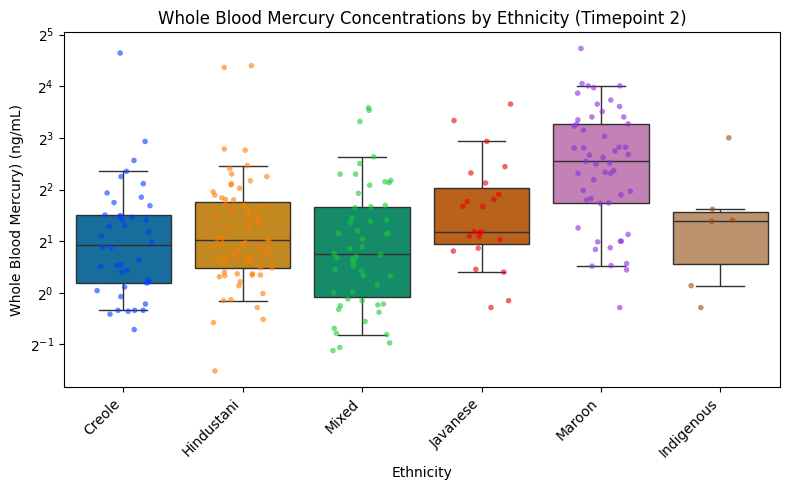

In [126]:
import matplotlib.ticker as ticker
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=mercury_exposure_t2,
    x="Ethnicity6",
    y="Hg(ng/mL)",
    hue="Ethnicity6",
    whis=[5,95],
    palette="colorblind",
    legend=False,
    fliersize=0,
    ax=ax
)

sns.stripplot(
    data=mercury_exposure_t2,
    x='Ethnicity6',
    y="Hg(ng/mL)",
    hue="Ethnicity6",
    jitter=0.25,
    alpha=0.6,
    size=4,
    ax=ax,
    dodge=False,  # keeps all tertiles on the same x-position instead of splitting
    legend=False,
    palette='bright'
)

ax.set_xlabel("Ethnicity")
ax.set_ylabel("Whole Blood Mercury) (ng/mL)")
ax.set_title("Whole Blood Mercury Concentrations by Ethnicity (Timepoint 2)")
ax.set_yscale("log",base=2)
#ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=10))
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

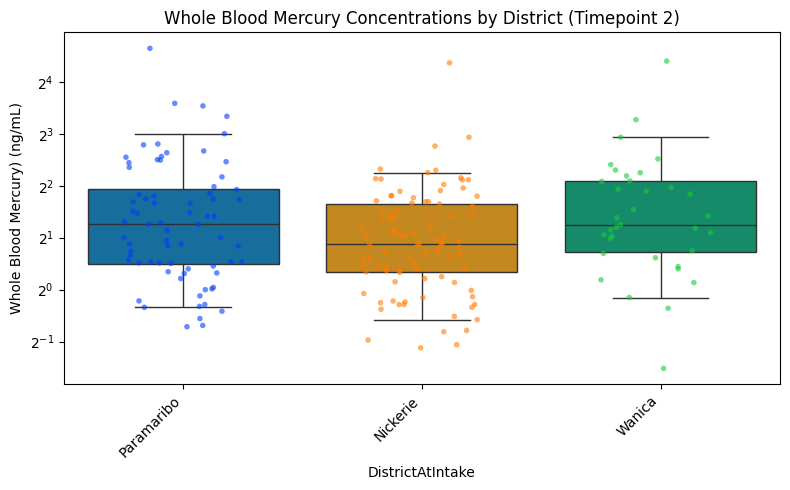

In [130]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=mercury_exposure_t2[mercury_exposure_t2['DistrictAtIntake'].isin(large_districts.index)],
    x="DistrictAtIntake",
    y="Hg(ng/mL)",
    hue="DistrictAtIntake",
    whis=[5,95],
    palette="colorblind",
    legend=False,
    fliersize=0,
    ax=ax
)

sns.stripplot(
    data=mercury_exposure_t2[mercury_exposure_t2['DistrictAtIntake'].isin(large_districts.index)],
    x='DistrictAtIntake',
    y="Hg(ng/mL)",
    hue="DistrictAtIntake",
    jitter=0.25,
    alpha=0.6,
    size=4,
    ax=ax,
    dodge=False,  # keeps all tertiles on the same x-position instead of splitting
    legend=False,
    palette='bright'
)

ax.set_xlabel("DistrictAtIntake")
ax.set_ylabel("Whole Blood Mercury) (ng/mL)")
ax.set_title("Whole Blood Mercury Concentrations by District (Timepoint 2)")
ax.set_yscale("log",base=2)
#ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=10))
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()